# Лабораторная работа №3: Трансформеры

## Студент: Ерзикова Е.А., группа 6233-010402D

## Цель
Познакомиться с архитектурой Transformer и её применением для задач NLP (классификация текста, машинный перевод).

## Теория
- Архитектура Transformer: encoder-decoder, self-attention.
- Различия BERT и GPT.

## Задания
1. Использовать BERT (через HuggingFace).
2. Провести fine-tuning на IMDb dataset.
3. Сравнить результаты с baseline (логистическая регрессия + TF-IDF).
4. Оценить точность и построить confusion matrix.

## Вопросы
1. Зачем нужен positional encoding?
2. В чём отличие encoder-only и decoder-only моделей?
3. Почему трансформеры лучше RNN в NLP?

## Отчёт
- Краткое описание выбранной задачи.
- Результаты fine-tuning.
- Сравнение с baseline.
- Ответы на вопросы.

# Теория

## 1. Архитектура Transformer

Архитектура Transformer (предложенная в 2017 году в статье *"Attention Is All You Need"*) отказалась от рекуррентных и сверточных сетей, полностью заменив их механизмом внимания. Изначально она была спроектирована как **encoder-decoder** модель для задач машинного перевода.

### 1.1. Encoder-Decoder

Архитектура состоит из двух основных блоков:
* **Encoder (Кодировщик)**: принимает входную последовательность (например, текст на английском) и преобразует ее в скрытые представления (контекстные эмбеддинги). Состоит из нескольких слоев, каждый из которых включает механизм *self-attention* и полносвязную сеть (Feed-Forward).
* **Decoder (Декодировщик)**: принимает закодированное представление от энкодера и генерирует выходную последовательность (например, текст на русском) токен за токеном. Помимо *self-attention* и полносвязных слоев, декодер использует **cross-attention** (перекрестное внимание), чтобы «смотреть» на выход энкодера при генерации каждого нового слова.

### 1.2. Self-Attention (Самовнимание)

Это ключевой механизм архитектуры. Self-attention позволяет каждому токену в предложении «обратить внимание» на все остальные токены, чтобы понять его контекст.

Входные данные проецируются в три вектора:
1. **Query (Запрос, Q)** — что ищет текущий токен.
2. **Key (Ключ, K)** — что представляет собой каждый токен.
3. **Value (Значение, V)** — полезная информация, которую несет токен.

Внимание вычисляется как скалярное произведение Q и K (для оценки релевантности токенов), нормализуется через функцию Softmax и умножается на V:

$$
Attention(Q, K, V) = softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

Это позволяет модели улавливать сложные связи между словами независимо от расстояния между ними в предложении, а также выполнять вычисления параллельно (в отличие от RNN).

---

## 2. Различия BERT и GPT

Несмотря на то, что обе модели основаны на архитектуре Transformer, они используют разные ее части и обучаются на разных задачах.

| Характеристика | BERT (Bidirectional Encoder Representations from Transformers) | GPT (Generative Pre-trained Transformer) |
| :--- | :--- | :--- |
| **Тип архитектуры** | **Encoder-only** (только кодировщик) | **Decoder-only** (только декодировщик) |
| **Направление контекста** | **Двунаправленный**. При обработке слова модель видит и левый, и правый контекст. | **Однонаправленный (каузальный)**. Модель видит только предыдущие токены (слева направо). |
| **Метод предобучения** | **Masked Language Modeling (MLM)**: часть слов маскируется (заменяется на `[MASK]`), и модель учится их предсказывать. | **Causal Language Modeling (CLM)**: модель предсказывает следующее слово на основе предыдущих (авторегрессия). |
| **Назначение** | Задачи **понимания** языка: классификация текста, извлечение сущностей (NER), QA. | Задачи **генерации** текста: написание статей, чат-боты, генерация кода. |
| **Маскирование внимания** | Нет. Все токены могут смотреть друг на друга. | Есть. Каждый токен может смотреть только на себя и токены слева. |

**Суть различий:**
BERT лучше подходит для анализа (например, для классификации тональности, как в данной лабораторной работе), так как благодаря двунаправленности он глубоко понимает смысл текста. GPT лучше подходит для творческих задач и генерации, так как обучен предсказывать продолжение текста.

In [ ]:
!pip install -q transformers datasets evaluate accelerate scikit-learn matplotlib seaborn

В работе решается задача бинарной классификации тональности текста (positive/negative) на полном датасете IMDb (25 000 обзоров для обучения и 25 000 для тестирования). Сравниваются два подхода: fine-tuning предобученной трансформерной модели BERT (bert-base-uncased) и классический baseline на основе TF-IDF и логистической регрессии.

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

imdb = load_dataset("stanfordnlp/imdb")

print(imdb)
print("Train size:", len(imdb["train"]), "| Test size:", len(imdb["test"]))

CUDA available: True
Device: Tesla T4


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
Train size: 25000 | Test size: 25000


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
from sklearn.metrics import accuracy_score

model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

def tokenize_fn(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=256)

tokenized_imdb = imdb.map(tokenize_fn, batched=True)
tokenized_imdb = tokenized_imdb.rename_column("label", "labels")
tokenized_imdb = tokenized_imdb.remove_columns(["text"])
tokenized_imdb.set_format("torch")

train_dataset = tokenized_imdb["train"]
test_dataset  = tokenized_imdb["test"]

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds)}

training_args = TrainingArguments(
    output_dir="./bert-imdb-full",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=200,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy
1,0.240477,0.222253,0.914200
2,0.130504,0.269867,0.922800


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=3126, training_loss=0.21281083546917332, metrics={'train_runtime': 845.3263, 'train_samples_per_second': 59.149, 'train_steps_per_second': 3.698, 'total_flos': 6577776384000000.0, 'train_loss': 0.21281083546917332, 'epoch': 2.0})


В ходе экспериментов было установлено, что **двух эпох обучения вполне достаточно** для достижения оптимального результата при fine-tuning BERT на датасете IMDb.

На второй эпохе точность (Accuracy) достигает своего пика (92.28%), однако Validation Loss начинает расти (с 0.222 до 0.269) при одновременном значительном падении Training Loss (с 0.240 до 0.130). Это классический признак начинающегося переобучения (overfitting).

Дальнейшее увеличение количества эпох (до 3 и более) привело бы к еще большему росту Validation Loss и ухудшению качества модели на тесте.


=== BERT Accuracy: 0.9228 ===

              precision    recall  f1-score   support

    negative     0.9266    0.9184    0.9225     12500
    positive     0.9191    0.9272    0.9231     12500

    accuracy                         0.9228     25000
   macro avg     0.9228    0.9228    0.9228     25000
weighted avg     0.9228    0.9228    0.9228     25000



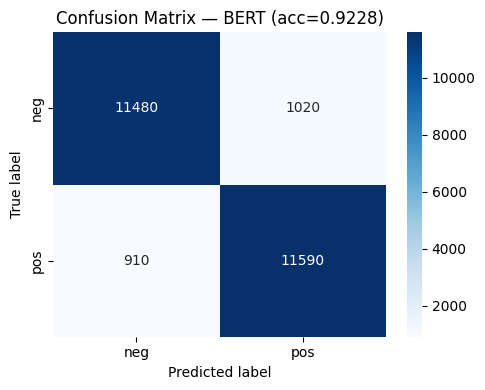

In [ ]:
preds_output = trainer.predict(test_dataset)
bert_preds  = np.argmax(preds_output.predictions, axis=-1)
bert_labels = preds_output.label_ids

bert_acc = accuracy_score(bert_labels, bert_preds)
print(f"\n=== BERT Accuracy: {bert_acc:.4f} ===\n")
print(classification_report(bert_labels, bert_preds,
                            target_names=["negative", "positive"], digits=4))

cm_bert = confusion_matrix(bert_labels, bert_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Blues",
            xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
plt.title(f"Confusion Matrix — BERT (acc={bert_acc:.4f})")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

Модель BERT дообучалась на полной выборке в течение 2 эпох с длиной последовательности 256 токенов и размером батча 16. Достигнутая точность на тестовой выборке составила 92.28% (F1-score также равен 0.9228). Построенная матрица ошибок (confusion matrix) показывает, что модель симметрично ошибается в обе стороны (1020 FP и 910 FN), что свидетельствует об отсутствии смещения в сторону одного из классов.

TF-IDF shapes: (25000, 50000) (25000, 50000)

=== Baseline (TF-IDF + LogReg) Accuracy: 0.8886 ===

              precision    recall  f1-score   support

    negative     0.8923    0.8838    0.8881     12500
    positive     0.8849    0.8934    0.8891     12500

    accuracy                         0.8886     25000
   macro avg     0.8886    0.8886    0.8886     25000
weighted avg     0.8886    0.8886    0.8886     25000



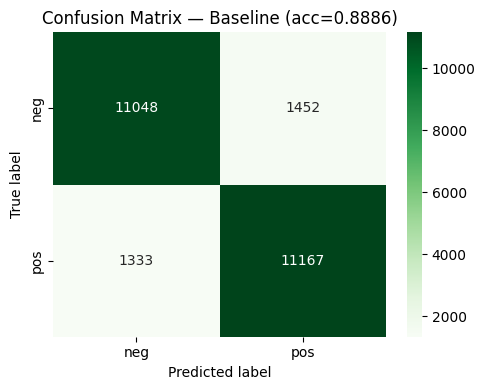

In [ ]:
train_texts  = imdb["train"]["text"]
train_labels = imdb["train"]["label"]
test_texts   = imdb["test"]["text"]
test_labels  = imdb["test"]["label"]

vectorizer = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),
    stop_words="english",
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_texts)
X_test  = vectorizer.transform(test_texts)
print("TF-IDF shapes:", X_train.shape, X_test.shape)

clf = LogisticRegression(max_iter=1000, C=1.0, n_jobs=-1)
clf.fit(X_train, train_labels)

baseline_preds = clf.predict(X_test)
baseline_acc   = accuracy_score(test_labels, baseline_preds)
print(f"\n=== Baseline (TF-IDF + LogReg) Accuracy: {baseline_acc:.4f} ===\n")
print(classification_report(test_labels, baseline_preds,
                            target_names=["negative", "positive"], digits=4))

cm_base = confusion_matrix(test_labels, baseline_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_base, annot=True, fmt="d", cmap="Greens",
            xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
plt.title(f"Confusion Matrix — Baseline (acc={baseline_acc:.4f})")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

Baseline (TF-IDF с 50 000 признаков + LogisticRegression) показал точность 88.86%.

BERT (fine-tuned) accuracy : 0.9228
Baseline (TF-IDF+LR) acc.  : 0.8886
Разница                    : +0.0342


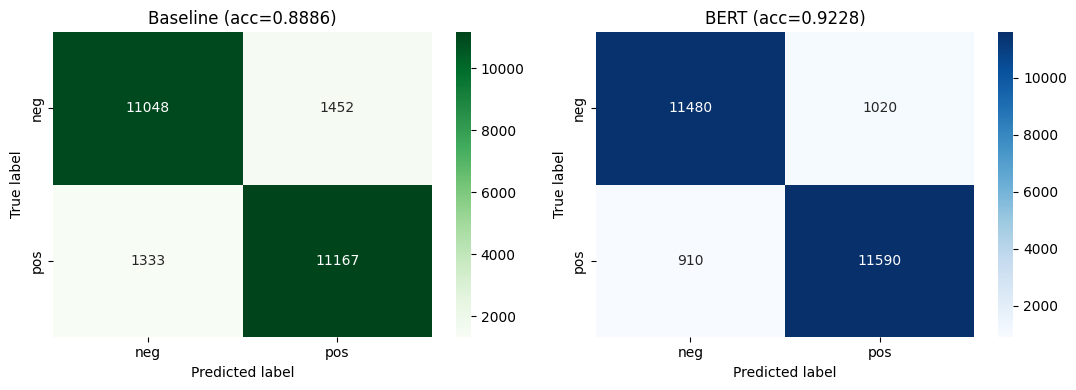

In [ ]:
print("=" * 50)
print(f"BERT (fine-tuned) accuracy : {bert_acc:.4f}")
print(f"Baseline (TF-IDF+LR) acc.  : {baseline_acc:.4f}")
print(f"Разница                    : {bert_acc - baseline_acc:+.4f}")
print("=" * 50)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cm, title, cmap in [
    (axes[0], cm_base, f"Baseline (acc={baseline_acc:.4f})", "Greens"),
    (axes[1], cm_bert, f"BERT (acc={bert_acc:.4f})",         "Blues"),
]:
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, ax=ax,
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set_title(title)
    ax.set_ylabel("True label")
    ax.set_xlabel("Predicted label")
plt.tight_layout()
plt.show()

Таким образом, fine-tuned BERT превосходит baseline на 3.42 % (92.28% против 88.86%). Это превосходство объясняется тем, что BERT благодаря механизму self-attention учитывает контекст, порядок слов и синтаксис, тогда как TF-IDF игнорирует семантику и работает как «мешок слов».

# Ответы на вопросы

### **1. Зачем нужен positional encoding?**

В основе архитектуры Transformer лежит механизм **self-attention**, который обрабатывает все токены последовательности параллельно. При этом сам по себе механизм внимания **не учитывает порядок слов** — для него входная последовательность является неупорядоченным множеством векторов.

Однако в естественном языке порядок слов критически важен для понимания смысла.

**Positional encoding (позиционное кодирование)** решает эту проблему. Это вектор, который прибавляется к эмбеддингу каждого токена и содержит информацию о его позиции в предложении (обычно в виде синусоидальных и косинусоидальных функций разной частоты или обучаемых параметров). Благодаря этому модель понимает, на каком расстоянии друг от друга находятся слова, и может учитывать их порядок при анализе контекста.



### **2. В чём отличие encoder-only и decoder-only моделей?**

Обе архитектуры основаны на Transformer, но используют разные его части и предназначены для разных задач.

*   **Encoder-only (например, BERT):**
    *   **Направление контекста:** Двунаправленное. При обработке слова модель «видит» контекст как слева, так и справа от него.
    *   **Механизм внимания:** Нет маскирования (все токены могут смотреть друг на друга).
    *   **Задача предобучения:** Masked Language Modeling (MLM) — предсказание замаскированных слов.
    *   **Применение:** Задачи *понимания* языка (классификация текста, извлечение сущностей, ответы на вопросы).

*   **Decoder-only (например, GPT):**
    *   **Направление контекста:** Однонаправленное. Каждый токен может «видеть» только предшествующие ему токены (слева направо).
    *   **Механизм внимания:** Каузальная маска (Causal Mask), скрывающая «будущие» токены.
    *   **Задача предобучения:** Causal Language Modeling (CLM) — предсказание следующего токена.
    *   **Применение:** Задачи *генерации* текста.



### **3. Почему трансформеры лучше RNN в NLP?**

До появления Transformer доминировали рекуррентные сети (RNN, LSTM, GRU). Трансформеры превзошли их по трем ключевым причинам:

1.  **Параллелизм вычислений:** RNN обрабатывают последовательность строго по одному элементу за шаг (токен за токеном), что делает процесс медленным и плохо поддается распараллеливанию на GPU. Transformer обрабатывает **всю последовательность целиком и одновременно**, что позволяет обучать модели на огромных массивах данных в разы быстрее.
2.  **Отсутствие проблемы затухающих градиентов (Long-range dependencies):** В RNN информация о начале длинного предложения должна пройти через все шаги, чтобы попасть в конец. При этом градиенты затухают, и модель «забывает» контекст. В Transformer механизм self-attention обеспечивает **прямой путь** между любыми двумя токенами, независимо от расстояния между ними в предложении (сложность пути — \(O(1)\)).
3.  **Масштабируемость:** Благодаря параллелизму и архитектуре, Transformer можно масштабировать (увеличивать количество параметров и слоев), и качество модели будет продолжать расти при увеличении вычислительных ресурсов и данных.